# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

In [2]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: c:\Users\ojh23\Documents\projects\llm-data-analysis-course\notebooks
프로젝트 루트: c:\Users\ojh23\Documents\projects\llm-data-analysis-course
전처리 데이터 폴더: c:\Users\ojh23\Documents\projects\llm-data-analysis-course\data\processed
그래프 저장 폴더: c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\figures


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [3]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic
완료 주문 상세 행: 446
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 6


In [4]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,141340000.0,141340000.0,0.0,True
1,product_linked_completed_amount,137325000.0,137325000.0,0.0,True
2,customer_completed_amount,141340000.0,141340000.0,0.0,True
3,monthly_completed_amount_valid_dates,139437000.0,139437000.0,0.0,True


In [5]:
viz_data["relationship_audit"]

,relationship,unmatched_rows,treatment
0,order_items -> orders,2,주문 상태·날짜를 알 수 없어 주문 기반 집계에서 제외
1,completed order items -> products,16,카테고리 집계에는 '상품 정보 없음'으로 포함; 상품 가격·수량 산점도에서는 제외


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과:
- 문제가 있었다면 원인:
- 시각화를 진행해도 된다고 판단한 이유:

- **총합 검증 결과:** 네 검증 항목의 `passed`가 모두 `True`이고 차이는 0입니다. 카테고리 및 고객 기준 완료 주문 금액은 각각 141,340,000원, 상품 정보가 연결된 완료 주문 금액은 137,325,000원, 유효한 주문일 기준 월별 금액은 139,437,000원입니다.
- **확인된 예외:** 주문과 연결되지 않은 주문 상세 2행은 주문 상태를 알 수 없어 주문 기반 분석에서 제외되었습니다. 상품 정보가 없는 완료 상세 16행은 카테고리 집계에서 `상품 정보 없음`으로 포함되지만 상품 단위 가격·수량 분석에서는 제외됩니다. 완료 상세 446행 중 주문일 결측 6행(1,903,000원)은 월별 집계에서 제외됩니다.
- **시각화를 진행해도 된다고 판단한 이유:** 분석 범위와 제외 기준을 관계 감사표에서 확인했고, 비교 가능한 집계 합계가 검증표에서 일치합니다. 예외 행과 월별 집계에서 제외된 금액도 기록해 결과의 범위를 설명할 수 있습니다.


## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [6]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
10,패션,290.0,32940000.0,23.31
7,식품,226.0,25035000.0,17.71
9,전자기기,176.0,21485000.0,15.20
0,도서,174.0,17663000.0,12.50
2,뷰티,168.0,17103000.0,12.10
6,스포츠,165.0,13237000.0,9.37
5,생활용품,108.0,7001000.0,4.95
3,상품 정보 없음,34.0,4015000.0,2.84
4,생활 용품,17.0,2108000.0,1.49
1,뷰 티,12.0,648000.0,0.46


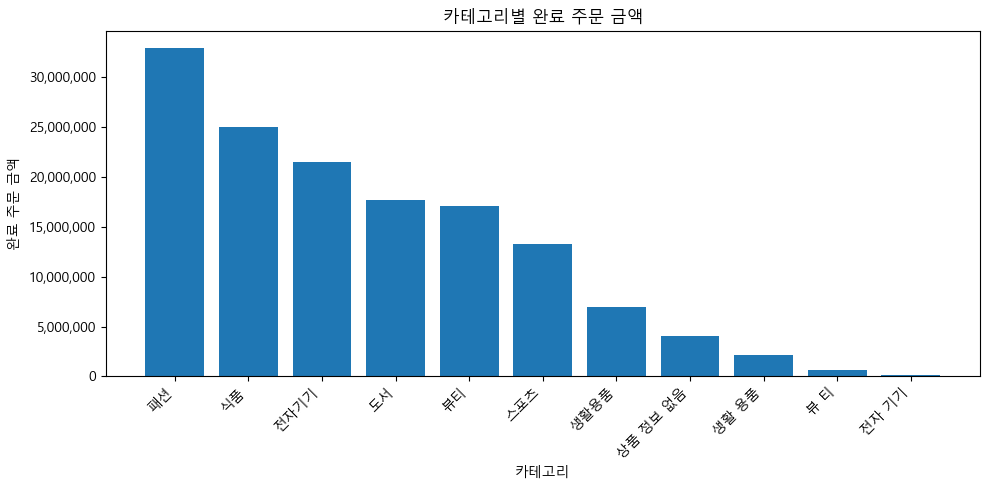

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_category_completed_amount_bar.png')

In [7]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** 실제 그래프와 집계표에서 직접 확인한 사실
- **해석:** 이 차이가 의미할 수 있는 내용
- **한계:** 금액만으로 알 수 없는 것
- **다음 질문:** 판매 수량·단가·상품 수 중 무엇을 더 확인할 것인가?

- **관찰:** 카테고리 완료 주문 금액 합계는 141,340,000원입니다. 패션 32,940,000원, 식품 25,035,000원, 전자기기 21,485,000원 순으로 큽니다. 상품 정보가 연결되지 않은 금액 4,015,000원은 별도 범주로 표시됩니다. 막대는 금액 내림차순입니다.
- **해석:** 관측된 완료 주문 금액이 카테고리별로 다르게 나타납니다. 띄어쓰기만 다른 카테고리명이 별도 범주로 집계되어 있어 표준화 여부를 추가 확인해야 합니다.
- **한계:** 금액만으로 판매 수량, 이익, 고객 선호도나 차이의 원인을 알 수 없습니다. 상품 정보가 없는 상세 16행은 개별 상품 분석에서 제외됩니다.
- **다음 질문:** 카테고리별 판매 수량, 상품 수, 평균 판매 단가를 함께 비교하면 금액 차이를 어떤 구성 차이가 설명하는가?


## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [8]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9561000.0,11,869182.0
1,2025-08,9362000.0,17,550706.0
2,2025-09,5299000.0,4,1324750.0
3,2025-10,12629000.0,17,742882.0
4,2025-11,9583000.0,16,598938.0
5,2025-12,8581000.0,12,715083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7247000.0,13,557462.0
9,2026-04,11459000.0,14,818500.0


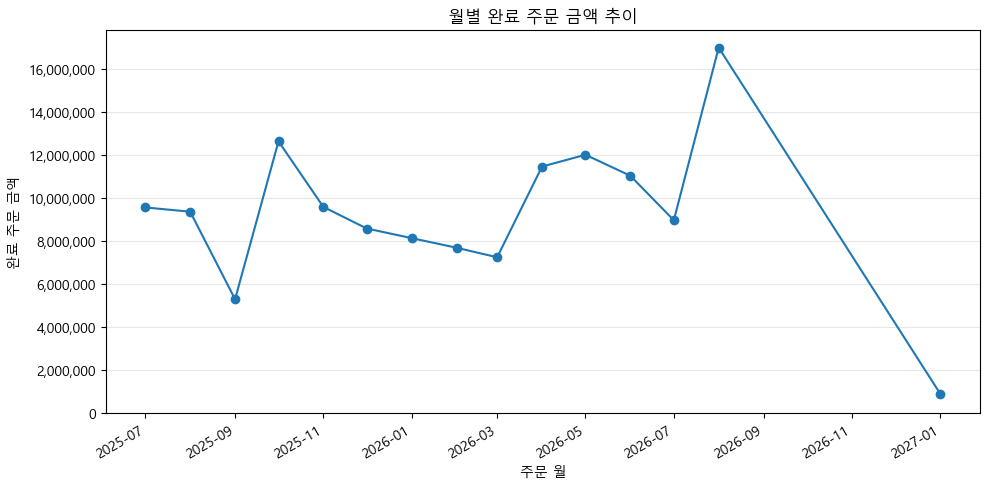

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png')

In [9]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

### 그래프 2 기록

- **관찰:** 증가·감소 또는 변곡이 실제로 보이는가?
- **해석:** 주문 수와 평균 주문 금액 중 무엇이 함께 변했는가?
- **한계:** 프로모션·계절성 등 현재 데이터에 없는 원인을 단정하지 않았는가?
- **다음 질문:** 추가로 확인할 지표는 무엇인가?

- **관찰:** 유효 날짜가 있는 완료 상세 440행의 월별 금액은 합계 139,437,000원입니다. 관측 월 중 2026년 8월이 16,980,000원(15건)으로 가장 크고, 2027년 1월은 909,000원(1건)입니다. 2026년 9~12월에는 집계 행이 없습니다.
- **해석:** 집계된 월들 사이에 금액 차이가 있습니다. 2026년 8월의 큰 금액은 해당 월 주문 수가 15건이라는 사실과 함께 볼 수 있지만, 주문 수와 평균 주문 금액 중 어느 요인이 차이를 설명하는지는 추가 비교가 필요합니다.
- **한계:** 2026년 9~12월은 실제 0원으로 확인된 것이 아니라 집계 행이 없는 기간입니다. 현재 그래프가 관측점을 연결하므로 그 구간의 실제 월별 추세를 보여 주는 것은 아닙니다. 프로모션이나 계절성을 원인으로 단정할 수 없습니다.
- **다음 질문:** 누락된 기간의 원본 주문 자료와 날짜 결측 6행을 확인하고, 월별 주문 수와 평균 주문 금액을 함께 비교하면 어떤 차이가 드러나는가?


## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [10]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

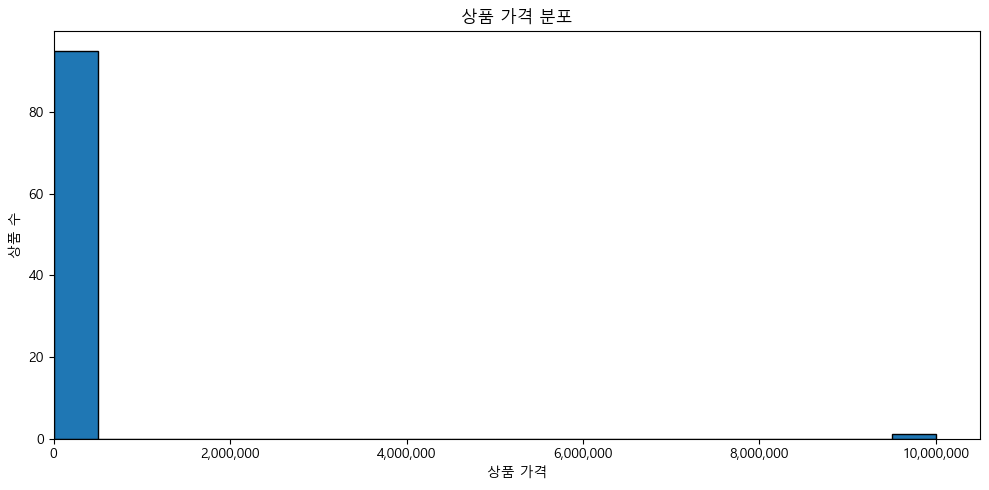

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [11]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

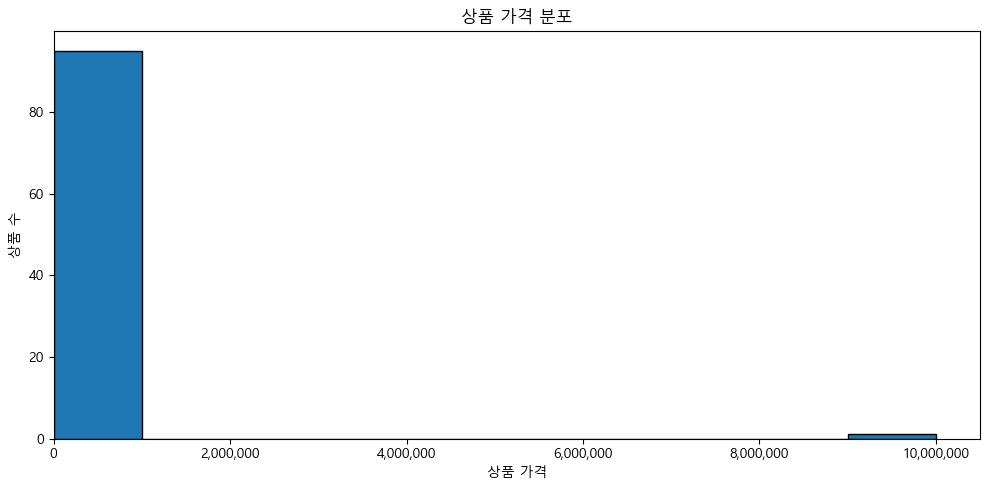

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [12]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=10,
)
price_hist_path

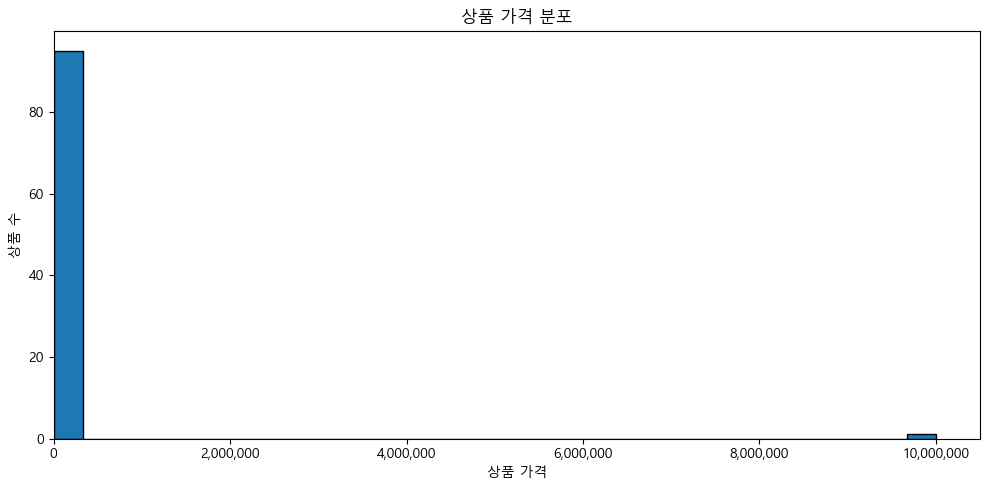

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [13]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=30,
)
price_hist_path

### bins 비교 실습

`bins=10`, `20`, `30` 그래프를 같은 상품 가격 데이터로 비교했습니다.

- **공통 패턴:** 세 그래프 모두 대부분의 상품 가격이 낮은 구간에 몰리고, 최댓값 9,999,999원인 하나의 큰 값이 오른쪽 끝까지 축을 늘리는 모습을 보입니다. 상품 가격은 96개이며 중앙값 94,500원, 75백분위수 153,250원으로 최댓값과 큰 차이가 있습니다.
- **bins에 따라 달라지는 인상:** `bins=10`은 구간이 넓어 낮은 가격대의 세부 분포가 더 뭉쳐 보입니다. `bins=20`과 `bins=30`은 구간을 더 잘게 나누지만, 극단적으로 큰 최댓값이 전체 축 범위를 차지해 낮은 가격대 안의 차이는 여전히 읽기 어렵습니다. 막대 경계와 높이는 bins 설정에 따라 달라집니다.
- **판단:** 구간 수 하나만으로 가격 분포를 확정하거나 최댓값을 오류로 단정하지 않습니다. 해당 가격을 원본 상품 자료에서 확인하고, 필요하면 축 범위를 달리한 보조 그래프를 함께 검토해야 합니다. 축 범위가 다른 그래프는 전체 분포 그래프를 대체하기보다 세부 구간을 보완하는 용도로 제시합니다.


## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [14]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
70,183000.0,37.0,6771000.0
90,96000.0,70.0,6720000.0
91,187000.0,26.0,4862000.0
61,193000.0,22.0,4246000.0
50,152000.0,26.0,3952000.0
66,168000.0,21.0,3528000.0
45,171000.0,19.0,3249000.0
36,172000.0,17.0,2924000.0
47,183000.0,15.0,2745000.0
81,145000.0,18.0,2610000.0


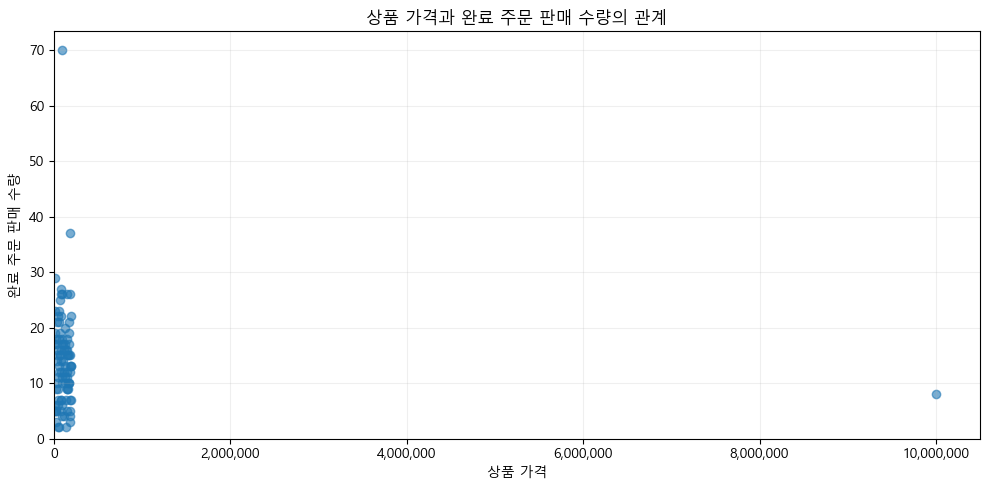

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png')

In [15]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 점들이 어떤 범위에 분포하는가?
- **해석:** 관계가 있어 보이는가, 뚜렷하지 않은가?
- **한계:** 카테고리·할인·노출·재고 등 다른 변수를 확인하지 않은 상태에서 무엇을 말할 수 없는가?
- **다음 질문:** 어떤 변수를 추가하면 관계를 더 잘 이해할 수 있는가?

- **관찰:** 점 하나는 상품 하나를 나타냅니다. 다수의 상품이 상대적으로 낮은 가격대에 모여 있으며, 가격 9,999,999원인 점이 x축 범위를 크게 넓혀 나머지 점들이 왼쪽에 밀집해 보입니다. 상품 연결 완료 상세 금액은 137,325,000원입니다.
- **해석:** 현재 그래프만으로 가격과 완료 판매 수량 사이의 뚜렷한 단순 선형 관계를 확인하기 어렵습니다.
- **한계:** 카테고리, 할인, 노출, 재고 같은 변수를 반영하지 않았고, 상품별 집계는 기간·판매 기회 차이도 통제하지 않습니다. 관계가 보이더라도 가격이 판매량의 원인이라고 할 수 없습니다.
- **다음 질문:** 가격을 원본에서 확인한 뒤 카테고리별로 나누고, 분석 기간·판매 가능 기간 및 할인·재고 자료를 추가하면 관계가 어떻게 달라지는가?


## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [16]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
1,3.0,3,6702000.0,2234000.0
7,14.0,4,5204000.0,1301000.0
57,90.0,3,4311000.0,1437000.0
59,93.0,4,4001000.0,1000250.0
47,65.0,6,3977000.0,662833.0
66,104.0,2,3966000.0,1983000.0
11,20.0,4,3808000.0,952000.0
27,38.0,4,3656000.0,914000.0
19,28.0,4,3201000.0,800250.0
13,22.0,3,3109000.0,1036333.0


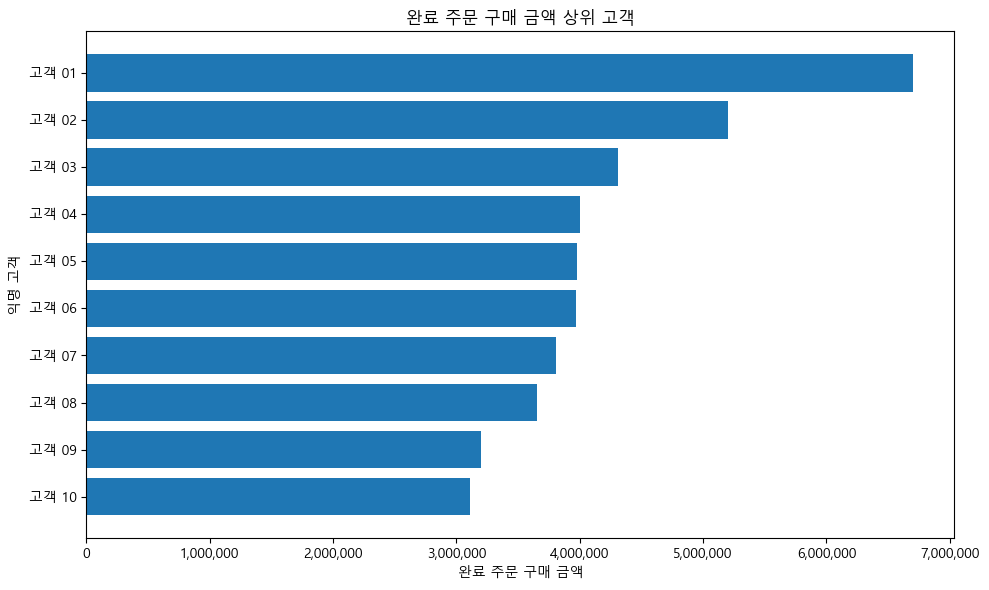

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_top_customers_anonymized_barh.png')

In [17]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [18]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


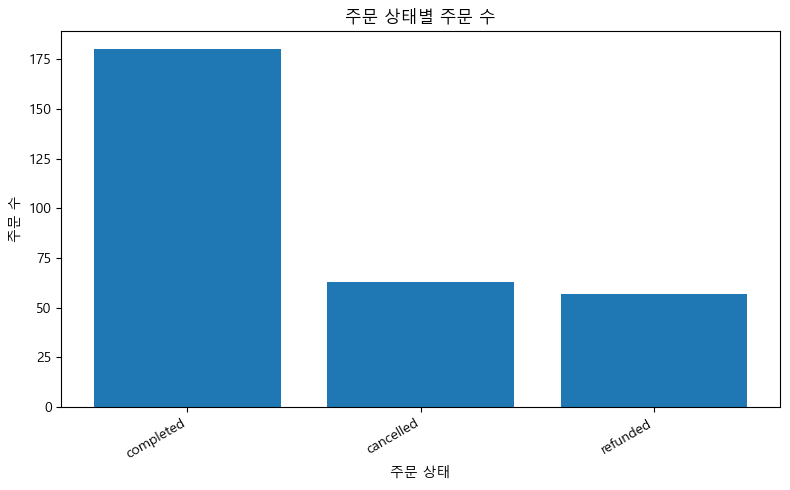

WindowsPath('c:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png')

In [19]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [20]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\figures\ch07_category_completed_amount_bar.png
- c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\figures\ch07_monthly_completed_amount_line.png
- c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\figures\ch07_product_price_hist.png
- c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\figures\ch07_price_completed_quantity_scatter.png
- c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\figures\ch07_top_customers_anonymized_barh.png
- c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\figures\ch07_order_status_bar.png
요약 보고서: c:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


## 11. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유
월별 완료 주문 금액 선그래프를 선택했습니다. 시간 순서에 따른 금액 차이를 확인하면서 날짜 결측과 집계가 없는 기간도 함께 검토할 수 있기 때문입니다.

### 그래프에서 직접 확인한 사실
유효 주문일 기준 월별 금액 합계는 139,437,000원입니다. 관측 월 중 2026년 8월이 16,980,000원으로 가장 높고 2027년 1월은 909,000원입니다. 날짜 결측 완료 상세 6행, 1,903,000원은 월별 합계에서 제외되었으며 2026년 9~12월에는 집계 행이 없습니다.

### 내가 해석한 내용
관측된 월 사이에는 금액 차이가 있습니다. 다만 월별 집계 행이 없는 기간은 0원으로 확인된 기간이 아니며, 선이 이어져 보이더라도 그 구간의 실제 변화를 나타낸다고 해석하지 않았습니다.

### 그래프만으로 말할 수 없는 것
금액 차이가 프로모션, 계절성, 가격, 재고 또는 고객 행동 때문에 발생했다고 단정할 수 없습니다. 집계 행이 없는 달의 매출이 0원이라고 말할 수 없고, 금액만으로 이익이나 고객 선호도를 판단할 수도 없습니다.

### 오해를 줄이기 위해 수정하거나 확인한 요소
- **축:** 금액 그래프의 값 축은 0부터 시작합니다. 산점도는 가격과 완료 판매 수량을 표시하고, 큰 가격값이 x축을 늘려 다른 점들을 압축해 보이게 합니다.
- **단위:** 금액은 원, 산점도의 수량 축은 완료 주문 판매 수량입니다. 축 제목에 원 표기가 직접 보이지 않는 금액 그래프는 수치 해석 시 원 단위를 확인해야 합니다.
- **정렬:** 카테고리 막대는 금액 내림차순, 월별 선그래프는 시간 오름차순입니다.
- **범위:** 월별 집계가 없는 2026년 9~12월을 0으로 채우지 않았습니다. 상품 가격 최댓값 9,999,999원은 히스토그램의 bins별 모양과 산점도 x축에 큰 영향을 줍니다. `bins=10·20·30`을 비교했고 공통 패턴과 구간 설정에 따른 차이를 구분했습니다.
- **개인정보:** 고객 금액 그래프는 순위 기반 익명 라벨을 사용합니다. 고객 집계표에는 학습용 고객 ID가 출력되므로 공개 범위에 맞게 확인해야 합니다.

### 다음 분석에서 확인하고 싶은 질문
2026년 9~12월의 집계 공백은 실제 주문이 없었던 것인지 자료가 누락된 것인지? 월별 주문 수와 평균 주문 금액을 함께 비교하면 금액 차이를 더 구체적으로 설명할 수 있는가?

---

## 완료 체크

- [x] 질문을 그래프보다 먼저 정했습니다.
- [x] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [x] 집계 검증표의 `passed`를 확인했습니다.
- [x] 대표 그래프 3개 이상을 만들었습니다.
- [x] 그래프와 원본 집계값을 교차 확인했습니다.
- [x] 축·단위·정렬·범위를 확인했습니다.
- [x] 관계를 원인으로 단정하지 않았습니다.
- [x] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [x] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [x] `reports/figures`와 요약 보고서 재생성 결과가 노트북에 출력되어 있음을 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.


# Chapter 07 답안 양식. 그래프로 데이터의 이야기를 보여주기

> 이 내용을 `chapter07.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
- 이름: `Byeonghui Oh`
- GitHub ID: `OBHAR`
- 작성일: `2026-10-20`
- 최종 Notebook URL: https://github.com/OBHAR/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 완료 주문 금액은 카테고리별로 어떻게 다른가? | 막대그래프 | 범주별 금액 크기와 순위를 비교하기 적합합니다. |
| 완료 주문 금액은 월별로 어떻게 변하는가? | 선그래프 | 시간 순서에 따른 월별 변화를 확인하기 적합합니다. |
| 상품 가격은 어떤 분포를 보이는가? | 히스토그램 | 가격이 어느 구간에 모이는지와 큰 값의 영향을 살펴보기 적합합니다. |

## 2. 대표 그래프 1
![대표 그래프 1](images/graph01.png)

### 원본 집계값
완료 주문 상세 기준 카테고리 합계는 141,340,000원입니다. 패션은 32,940,000원(23.31%), 식품은 25,035,000원(17.71%), 전자기기는 21,485,000원(15.20%)입니다. 상품 정보가 없는 상세 금액 4,015,000원도 별도 범주로 포함됩니다.

### 결과 관찰
막대는 완료 주문 금액 내림차순입니다. 패션이 가장 크고 식품과 전자기기가 뒤를 잇습니다. 띄어쓰기 차이가 있는 카테고리명은 각각 별도 막대로 표시됩니다.

### 나의 해석과 판단
관측된 카테고리별 금액 차이를 확인했습니다. 표기가 다른 범주가 실제로 서로 다른지 확인되지 않았으며, 금액 순위만으로 선호도나 수익성을 판단하지 않았습니다.

### 업무·분석적 의미
금액 규모가 큰 카테고리를 판매 수량, 상품 수, 평균 단가 분석의 후속 대상으로 정할 수 있습니다. 상품 연결 누락 금액도 점검 대상입니다.

### 한계와 추가 확인 사항
카테고리 표기의 일관성과 상품 정보가 연결되지 않은 상세 16행을 확인해야 합니다. 매출 금액만으로 판매량, 이익, 할인 효과나 고객 선호를 판단할 수 없습니다.

## 3. 대표 그래프 2
![대표 그래프 2](images/graph02.png)

### 원본 집계값
완료 주문 상세 446행 중 주문일 유효 440행의 월별 금액 합계는 139,437,000원입니다. 날짜 결측 6행의 금액 1,903,000원은 월별 집계에서 제외됩니다. 관측 월 중 2026년 8월이 16,980,000원(15건)으로 가장 높고, 2027년 1월은 909,000원(1건)입니다.

### 결과 관찰
월별 금액은 관측된 달마다 차이가 있습니다. 2026년 9~12월에는 집계 행이 없으며, 그래프의 선은 2026년 8월과 2027년 1월 관측점을 연결합니다.

### 나의 해석과 판단
관측 월 사이의 금액 차이는 확인할 수 있지만, 집계 행이 없는 달을 0원으로 보거나 연결된 선을 해당 기간의 실제 추세로 해석하지 않았습니다.

### 업무·분석적 의미
월별 금액과 주문 수, 평균 주문 금액을 함께 비교하면 금액 차이가 주문 건수와 건당 금액 중 무엇과 함께 변하는지 살펴볼 수 있습니다. 날짜 결측 행도 별도로 관리해야 합니다.

### 한계와 추가 확인 사항
2026년 9~12월에 주문이 없었는지 자료가 누락되었는지는 원본 주문 자료로 확인해야 합니다. 첫·마지막 달이 부분 기간인지도 확인해야 하며, 프로모션이나 계절성을 원인으로 단정할 수 없습니다.

## 4. 대표 그래프 3
![대표 그래프 3](images/graph03.png)

### 원본 집계값
상품 마스터의 가격 96개를 사용했습니다. 중앙값은 94,500원, 평균은 약 204,896원, 75백분위수는 153,250원, 최솟값은 5,000원, 최댓값은 9,999,999원입니다. 히스토그램은 동일한 가격 데이터에서 `bins=10`, `20`, `30`으로 비교했습니다.

### 결과 관찰
세 설정에서 대부분의 가격이 낮은 구간에 모이고 최댓값이 오른쪽 끝에 분리되어 보이는 공통 패턴이 유지됩니다. bins가 커질수록 구간이 세분되지만, 극단적으로 큰 최댓값 때문에 x축 범위가 넓어 낮은 가격대의 세부 차이는 여전히 읽기 어렵습니다.

### 나의 해석과 판단
분포가 큰 가격값의 영향을 받는다는 점을 확인했습니다. bins에 따라 막대 경계와 높이가 달라지므로 하나의 설정만으로 분포를 확정하지 않았고, 최댓값을 오류라고 단정하지 않았습니다.

### 업무·분석적 의미
대표 가격대와 분포의 치우침을 파악하고, 매우 큰 가격값을 원본 상품 자료에서 점검할 수 있습니다. 필요하면 전체 분포 그래프와 낮은 가격대 보조 그래프를 함께 제시할 수 있습니다.

### 한계와 추가 확인 사항
최댓값이 실제 가격인지 원본을 확인해야 합니다. 히스토그램의 모양은 bins와 축 범위에 영향을 받습니다. 축 범위를 바꾼 보조 그래프는 전체 분포를 대체하지 않도록 함께 해석해야 합니다.

## 5. 그래프 정확성 점검
- [x] 그래프 값과 집계표 값 일치
- [x] 축 이름 확인
- [x] 단위 확인
- [x] 범례 확인
- [x] 날짜 정렬 확인
- [x] 과장될 수 있는 축 범위 확인
- [x] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점
검증표의 네 금액 검증 항목은 모두 `passed=True`이며 차이는 0입니다. 금액 그래프 축은 0부터 시작하고 금액 단위는 원입니다. 카테고리 막대는 내림차순, 월별 그래프는 시간순으로 정렬되어 있습니다. 2026년 9~12월은 집계 행이 없으므로 0으로 간주하지 않았습니다. 가격 최댓값 9,999,999원은 히스토그램과 산점도 범위에 영향을 줍니다. bins 10·20·30 비교로 구간 설정에 따른 표현 차이를 확인했습니다. 고객 그래프는 순위 기반 익명 라벨을 사용합니다.

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유
월별 완료 주문 금액 선그래프를 선택했습니다. 시간 순서의 금액 차이와 날짜 결측, 집계가 없는 기간을 함께 점검할 수 있기 때문입니다.

### 그래프가 보여 준 사실
유효 날짜 월별 금액 합계는 139,437,000원이며 관측 월 중 2026년 8월이 16,980,000원으로 가장 높습니다. 날짜 결측 완료 상세 6행, 1,903,000원은 월별 합계에서 제외되었고 2026년 9~12월은 집계 행이 없습니다.

### 그래프만으로 말할 수 없는 것
월별 금액 차이의 원인이 프로모션, 계절성, 가격, 재고 또는 고객 행동이라고 단정할 수 없습니다. 집계가 없는 달의 금액이 0이라고 말할 수도 없습니다.

### 다음 분석에서 확인할 질문
2026년 9~12월의 주문 자료와 날짜 결측 상세의 원인을 확인하고, 월별 주문 수와 평균 주문 금액을 함께 비교하면 금액 차이를 더 구체적으로 설명할 수 있는가?

## 최종 체크
- [x] 그래프와 수치를 교차 검증했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.
